# Training curves: TinySkies

Metric histories of the runs that produced the released TinySkies models, exported from the original training logs into `results/<run_id>/` (see `PROVENANCE.md`). The CARLA `world_v3` history was not recoverable; its only surviving record is a screenshot, shown at the end.

Both TinySkies models come from **resumed run chains**: each run continues from the previous run's checkpoint.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
from eval import plotstyle as ps

ps.apply()
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
pd.set_option("display.precision", 4)


In [2]:
def load(run):
    h = pd.read_csv(Path(run) / "history.csv")
    return h, json.loads((Path(run) / "config.json").read_text())

VAE_CHAIN = ["3ixb3s35", "y0lnd3md", "yvxlfm52"]
SIM_STAGE1 = ["jl1spotp", "0b8k4g16", "u8qj3r6l"]          # VAE epoch 6, rollout horizon 13
SIM_STAGE2 = ["7mi5pz2h", "dukugksc"]                      # VAE epoch 15, rollout horizon 128 (resumed at epoch 26)
DEPLOYED_SIM_EPOCH, DEPLOYED_VAE_EPOCHS = 40, 14

def chain(runs):
    return pd.concat([load(r)[0].assign(run=r) for r in runs], ignore_index=True)

vae, s1, s2 = chain(VAE_CHAIN), chain(SIM_STAGE1), chain(SIM_STAGE2)
pd.DataFrame(
    [
        {"model": "VAE", "runs": " → ".join(VAE_CHAIN), "epochs": f"{vae['progress/epoch'].min():.0f}–{vae['progress/epoch'].max():.0f}",
         "steps": f"{vae['progress/batch_step'].max():,.0f}", "note": "deployed = weights after epoch 14"},
        {"model": "latent sim, stage 1", "runs": " → ".join(SIM_STAGE1), "epochs": f"{s1['progress/epoch'].min():.0f}–{s1['progress/epoch'].max():.0f}",
         "steps": f"{s1['progress/batch_step'].max():,.0f}", "note": "VAE epoch 6 latents, horizon 13"},
        {"model": "latent sim, stage 2", "runs": " → ".join(SIM_STAGE2), "epochs": f"{s2['progress/epoch'].min():.0f}–{s2['progress/epoch'].max():.0f}",
         "steps": f"{s2['progress/batch_step'].max():,.0f}", "note": "VAE epoch 15 latents, horizon 128; deployed = epoch 40"},
    ]
)

,model,runs,epochs,steps,note
0,VAE,3ixb3s35 → y0lnd3md → yvxlfm52,1–15,"233,900",deployed = weights after epoch 14
1,"latent sim, stage 1",jl1spotp → 0b8k4g16 → u8qj3r6l,1–28,"26,250","VAE epoch 6 latents, horizon 13"
2,"latent sim, stage 2",7mi5pz2h → dukugksc,26–42,"42,750","VAE epoch 15 latents, horizon 128; deployed = ..."


## VAE reconstruction loss

L1 reconstruction (the KL term has weight 1e-5). Validation uses held-out sessions.

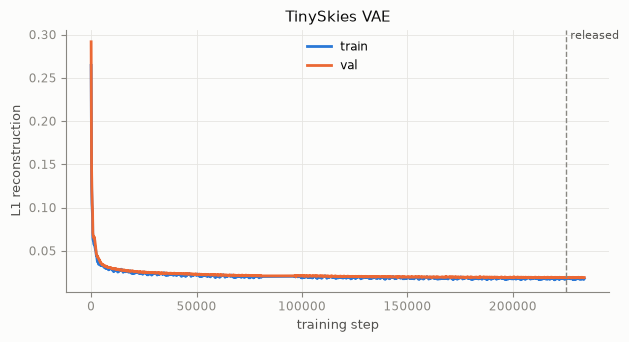

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for split, color in (("train", ps.BLUE), ("val", ps.ORANGE)):
    d = vae.dropna(subset=[f"{split}/recon_loss"])
    ax.plot(d["progress/batch_step"], d[f"{split}/recon_loss"].rolling(15, min_periods=1).mean(), color=color, label=split)
end14 = vae.loc[vae["progress/epoch_completed"] == DEPLOYED_VAE_EPOCHS, "_step"]
if len(end14):
    ax.axvline(end14.iloc[0], color=ps.MUTED, ls="--", lw=1)
    ax.text(end14.iloc[0], ax.get_ylim()[1], " released", color=ps.INK_2, va="top", fontsize=8)
ax.set(xlabel="training step", ylabel="L1 reconstruction", title="TinySkies VAE")
ax.legend()
fig.savefig(FIGURES / "tinyskies_vae_loss.png")

## Latent simulator: one-step vs. end-of-rollout error

Every training step unrolls the model on its own predictions. `one_step` is the latent MSE of the first prediction, `final_step` of the last one (step 13 in stage 1, step 128 in stage 2). The gap between them is the compounding error that a one-step metric hides. Stage 1 and stage 2 losses are not directly comparable: the horizon and the latent space (VAE epoch 6 vs. 15) both change at epoch 26.

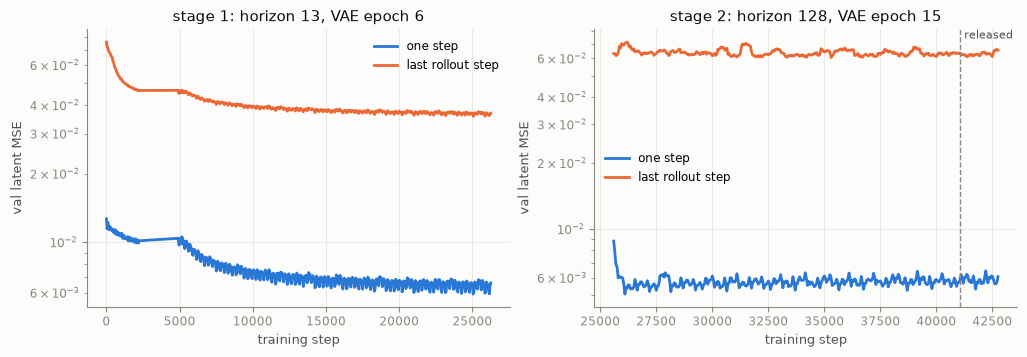

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
for ax, d, title in ((axes[0], s1, "stage 1: horizon 13, VAE epoch 6"), (axes[1], s2, "stage 2: horizon 128, VAE epoch 15")):
    v = d.dropna(subset=["val/one_step_latent_loss"])
    ax.plot(v["progress/batch_step"], v["val/one_step_latent_loss"].rolling(9, min_periods=1).mean(), color=ps.BLUE, label="one step")
    ax.plot(v["progress/batch_step"], v["val/final_step_latent_loss"].rolling(9, min_periods=1).mean(), color=ps.ORANGE, label="last rollout step")
    ax.set(xlabel="training step", ylabel="val latent MSE", title=title, yscale="log")
    ax.legend()
released_step = s2.loc[s2["progress/epoch_completed"] == DEPLOYED_SIM_EPOCH, "_step"].iloc[0]
axes[1].axvline(released_step, color=ps.MUTED, ls="--", lw=1)
axes[1].text(released_step, axes[1].get_ylim()[1], " released", color=ps.INK_2, va="top", fontsize=8)
fig.savefig(FIGURES / "tinyskies_sim_one_vs_final.png")

In [5]:
rows = []
for name, d in (("stage 1", s1), ("stage 2", s2)):
    v = d.dropna(subset=["val/latent_loss"])
    last = v[v["progress/epoch"] >= v["progress/epoch"].max() - 1]
    rows.append({"stage": name, "epochs": f"{last['progress/epoch'].min():.0f}–{last['progress/epoch'].max():.0f}",
                 "val one-step": last["val/one_step_latent_loss"].mean(), "val last-step": last["val/final_step_latent_loss"].mean(),
                 "ratio last/one": last["val/final_step_latent_loss"].mean() / last["val/one_step_latent_loss"].mean(),
                 "val mean over rollout": last["val/latent_loss"].mean()})
at = s2[(s2["progress/epoch"] >= DEPLOYED_SIM_EPOCH - 1) & (s2["progress/epoch"] < DEPLOYED_SIM_EPOCH)].dropna(subset=["val/latent_loss"])
rows.append({"stage": "released (epoch 40)", "epochs": "39–40", "val one-step": at["val/one_step_latent_loss"].mean(),
             "val last-step": at["val/final_step_latent_loss"].mean(),
             "ratio last/one": at["val/final_step_latent_loss"].mean() / at["val/one_step_latent_loss"].mean(),
             "val mean over rollout": at["val/latent_loss"].mean()})
table = pd.DataFrame(rows)
table.to_csv(FIGURES / "tinyskies_training_table.csv", index=False)
table

,stage,epochs,val one-step,val last-step,ratio last/one,val mean over rollout
0,stage 1,27–28,0.0065,0.0368,5.6515,0.0259
1,stage 2,41–42,0.0059,0.0632,10.7827,0.0500
2,released (epoch 40),39–40,0.0059,0.0625,10.5524,0.0497


## CARLA `world_v3` (screenshot only)

The run history of the released CARLA model was not recoverable. This W&B panel screenshot (evidence class **Q**) was taken on 2026-05-18, after the epoch-20 checkpoint was exported, and may show a run that continued past it. It is shown for completeness; no number in the paper is read from it.

(np.float64(-0.5), np.float64(2765.5), np.float64(1347.5), np.float64(-0.5))

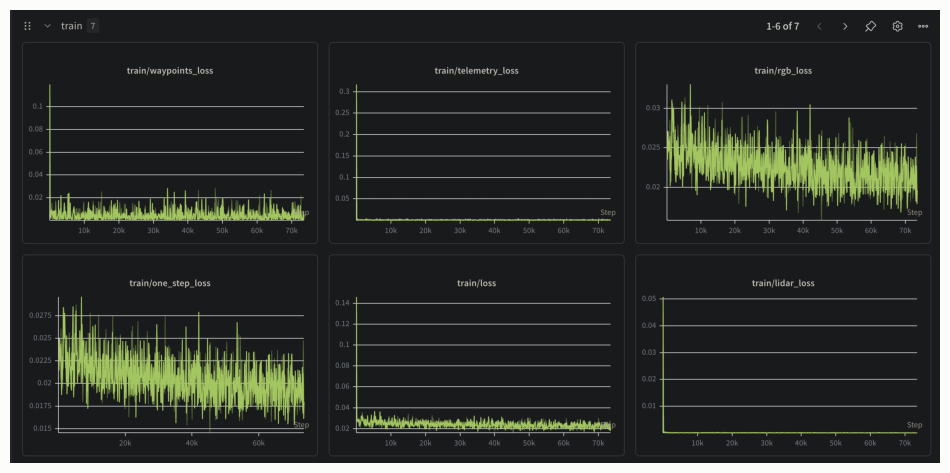

In [6]:
from PIL import Image
img = Image.open("carla_world_v3/wandb_train_panel_screenshot.png")
fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(img); ax.axis("off")